- **Гипотеза 1.** Можно ли увеличить количество аренды в такие часы как с 8 до 9 и с 18 до 19 тариф на работу и домой.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

- читаю файл "../../../data_after_preprocessing/drd_with_weather.parquet"

In [2]:
drd_with_weather = pd.read_parquet('../../../data_after_preprocessing/drd_with_weather.parquet')
drd_with_weather

,rideable_type,started_at,ended_at,member_casual,date,temp,feelslike,humidity,dew,visibility,windspeed,precipcover,snow,icon,duration_in_minutes
0,docked_bike,2020-05-30 17:25:29.000,2020-05-31 18:25:22.000,casual,2020-05-30,24.299999,24.100000,55.700001,13.800000,16.0,32.700001,4.17,0.0,rain,1499.883301
1,docked_bike,2020-05-09 14:42:04.000,2020-05-09 15:06:33.000,member,2020-05-09,6.800000,3.600000,41.900002,-5.700000,16.0,40.799999,0.00,0.0,partly-cloudy-day,24.483334
2,docked_bike,2020-05-24 17:27:19.000,2020-05-24 17:43:51.000,member,2020-05-24,18.000000,18.000000,82.300003,14.900000,15.8,20.900000,0.00,0.0,cloudy,16.533333
3,docked_bike,2020-05-27 15:29:52.000,2020-05-27 15:47:13.000,casual,2020-05-27,22.200001,22.200001,79.199997,18.200001,15.8,17.500000,0.00,0.0,partly-cloudy-day,17.350000
4,docked_bike,2020-05-31 14:06:03.000,2020-05-31 14:30:30.000,casual,2020-05-31,20.400000,20.400000,39.500000,6.000000,16.0,28.500000,0.00,0.0,partly-cloudy-day,24.450001
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
16086667,electric_bike,2024-08-01 08:10:22.293,2024-08-01 08:10:37.641,member,2024-08-01,29.600000,31.900000,64.500000,21.600000,15.9,17.100000,0.00,0.0,partly-cloudy-day,0.255800
16086668,electric_bike,2024-08-08 10:05:21.938,2024-08-08 10:21:46.654,member,2024-08-08,25.900000,26.200001,86.000000,23.400000,13.6,20.000000,50.00,0.0,rain,16.411934
16086669,electric_bike,2024-08-03 16:29:32.252,2024-08-03 16:35:43.179,member,2024-08-03,27.900000,30.000000,71.099998,21.900000,15.7,34.599998,12.50,0.0,rain,6.182117
16086670,electric_bike,2024-08-03 02:49:45.661,2024-08-03 02:59:56.877,member,2024-08-03,27.900000,30.000000,71.099998,21.900000,15.7,34.599998,12.50,0.0,rain,10.186934


- добавляю новый столбец started_at_time

In [3]:
drd_with_weather['started_at_time'] = drd_with_weather['started_at'].dt.hour

- добавляю новый столбец ended_at_time

In [4]:
drd_with_weather['ended_at_time'] = drd_with_weather['ended_at'].dt.hour

- вывожу график и смотрю сколько совершено поездок в разные часы

<Axes: xlabel='started_at_time'>

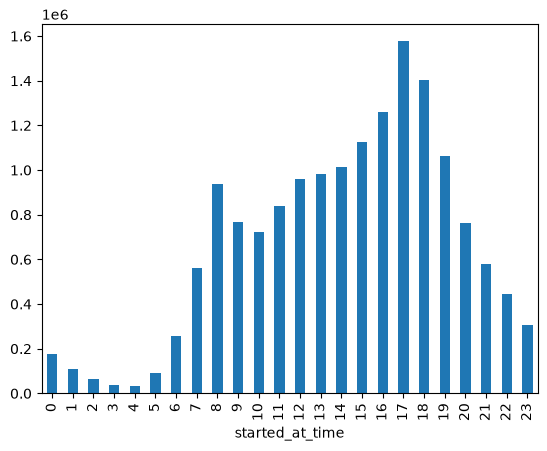

In [5]:
drd_with_weather['started_at_time'].value_counts().sort_index(ascending=True).plot(kind='bar')

- выбираю данные с 8 часов до 9 включительно

In [6]:
ride_to_work = drd_with_weather[
    drd_with_weather['started_at_time'].between(8, 9) &
    drd_with_weather['ended_at_time'].between(8, 9)
]

- проверяю правильно ли я выбрал время

In [7]:
ride_to_work['started_at_time'].unique(), ride_to_work['ended_at_time'].unique()

(array([8, 9], dtype=int32), array([9, 8], dtype=int32))

- смотрю сколько совершили поездок member и casual

In [8]:
ride_to_work['member_casual'].value_counts()

member_casual
member    1122668
casual     396674
Name: count, dtype: int64

- группирую данные по столбцам rideable_type и member_casual и считаю разную агрегацию по столбцу duration_in_minutes

In [9]:
ride_to_work_group = ride_to_work.groupby(
    ['rideable_type', 'member_casual']
)['duration_in_minutes'].agg(['mean', 'median', 'max', 'min', 'count'])

ride_to_work_group

mean     median           max  min   count
rideable_type member_casual                                                 
classic_bike  casual         16.726273  11.333333   1499.958130  0.0  228687
              member         11.455994   8.966666   1499.966675  0.0  770033
docked_bike   casual         24.792271  16.233334  30126.250000  0.0   42038
              member         12.300637  10.000000   1499.916626  0.0   62714
electric_bike casual         12.103509   9.966666    113.800003  0.0  125949
              member         10.848647   9.078150    113.349998  0.0  289921

- выбираю данные с 17 часов до 18 включительно

In [10]:
ride_to_home = drd_with_weather[
    drd_with_weather['started_at_time'].between(17, 18) &
    drd_with_weather['ended_at_time'].between(17, 18)
]

- проверяю правильно ли я выбрал время

In [11]:
ride_to_home['started_at_time'].unique(), ride_to_home['ended_at_time'].unique()

(array([17, 18], dtype=int32), array([18, 17], dtype=int32))

- смотрю сколько совершили поездок member и casual

In [12]:
ride_to_home['member_casual'].value_counts()

member_casual
member    1690676
casual     918689
Name: count, dtype: int64

- группирую данные по столбцам rideable_type и member_casual и считаю разную агрегацию по столбцу duration_in_minutes

In [13]:
ride_to_home_group = ride_to_home.groupby(
    ['rideable_type', 'member_casual']
)['duration_in_minutes'].agg(['mean', 'median', 'max', 'min', 'count'])

ride_to_home_group

mean     median            max  min    count
rideable_type member_casual                                                   
classic_bike  casual         20.845751  14.016666    1507.766724  0.0   509881
              member         12.179723   9.350000    1499.949951  0.0  1113822
docked_bike   casual         35.856647  20.683332  188619.046875  0.0   144402
              member         15.254042  10.900000  197314.953125  0.0   116635
electric_bike casual         14.174569  11.016666     119.050003  0.0   264406
              member         11.845084   9.383333     116.933334  0.0   460219

- выбираю данные которые не входят с 8 часов до 9 включительно и с 17 часов до 18 включительно

In [14]:
excluded = [8, 9, 17, 18]
ride_without_work = drd_with_weather[
    ~drd_with_weather['started_at_time'].isin(excluded) &
    ~drd_with_weather['ended_at_time'].isin(excluded)
]

- вывожу результат

In [15]:
ride_without_work

,rideable_type,started_at,ended_at,member_casual,date,temp,feelslike,humidity,dew,visibility,windspeed,precipcover,snow,icon,duration_in_minutes,started_at_time,ended_at_time
1,docked_bike,2020-05-09 14:42:04.000,2020-05-09 15:06:33.000,member,2020-05-09,6.800000,3.600000,41.900002,-5.700000,16.0,40.799999,0.000000,0.0,partly-cloudy-day,24.483334,14,15
3,docked_bike,2020-05-27 15:29:52.000,2020-05-27 15:47:13.000,casual,2020-05-27,22.200001,22.200001,79.199997,18.200001,15.8,17.500000,0.000000,0.0,partly-cloudy-day,17.350000,15,15
4,docked_bike,2020-05-31 14:06:03.000,2020-05-31 14:30:30.000,casual,2020-05-31,20.400000,20.400000,39.500000,6.000000,16.0,28.500000,0.000000,0.0,partly-cloudy-day,24.450001,14,14
5,docked_bike,2020-05-30 20:23:38.000,2020-05-30 20:46:36.000,casual,2020-05-30,24.299999,24.100000,55.700001,13.800000,16.0,32.700001,4.170000,0.0,rain,22.966667,20,20
7,docked_bike,2020-05-23 14:42:17.000,2020-05-23 15:52:05.000,casual,2020-05-23,22.799999,22.799999,72.300003,16.900000,15.6,22.900000,20.830000,0.0,rain,69.800003,14,15
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
16086666,electric_bike,2024-08-09 21:48:44.578,2024-08-09 22:14:06.567,member,2024-08-09,27.000000,28.799999,82.400002,23.700001,13.9,37.900002,58.330002,0.0,rain,25.366484,21,22
16086668,electric_bike,2024-08-08 10:05:21.938,2024-08-08 10:21:46.654,member,2024-08-08,25.900000,26.200001,86.000000,23.400000,13.6,20.000000,50.000000,0.0,rain,16.411934,10,10
16086669,electric_bike,2024-08-03 16:29:32.252,2024-08-03 16:35:43.179,member,2024-08-03,27.900000,30.000000,71.099998,21.900000,15.7,34.599998,12.500000,0.0,rain,6.182117,16,16
16086670,electric_bike,2024-08-03 02:49:45.661,2024-08-03 02:59:56.877,member,2024-08-03,27.900000,30.000000,71.099998,21.900000,15.7,34.599998,12.500000,0.0,rain,10.186934,2,2


- считаю долю поездок на работу и домой от всех аренд велосипедов

In [35]:
((len(ride_to_work) + len(ride_to_work)) / len(ride_without_work)) * 100

28.040115099155972

- проверяю правильно ли осталичь только те часы которые не входят в поездки на работу и домой

In [16]:
np.sort(ride_without_work['started_at_time'].unique())

array([ 0,  1,  2,  3,  4,  5,  6,  7, 10, 11, 12, 13, 14, 15, 16, 19, 20,
       21, 22, 23], dtype=int32)

- группирую данные по столбцам rideable_type и member_casual и считаю разную агрегацию по столбцу duration_in_minutes (для всех остальных данных)

In [17]:
ride_without_work_group = ride_without_work.groupby(
    ['rideable_type', 'member_casual']
)['duration_in_minutes'].agg(['mean', 'median', 'max', 'min', 'count'])

ride_without_work_group

mean     median            max  min    count
rideable_type member_casual                                                   
classic_bike  casual         30.595669  15.716666    1559.949951  0.0  2333033
              member         13.436054   8.933333    1559.900024  0.0  4008026
docked_bike   casual         88.523117  25.350000  296815.406250  0.0   813309
              member         23.555756  10.933333  242008.828125  0.0   468908
electric_bike casual         16.898506  11.216666    1270.683350  0.0  1249624
              member         12.506025   9.066667    1275.566650  0.0  1964017

- считаю во сколько раз будет отличатся поездки в минутах (здесь делю данные всех остальных поездок на поездки на работу)

In [18]:
df_heat = ride_without_work_group / ride_to_work_group

- сбрасываю индексы

In [19]:
df_heat = df_heat.reset_index()

- убираю docked_bike из данных

In [20]:
df_heat = df_heat[df_heat['rideable_type'] != 'docked_bike']

- строю график (bar plot)

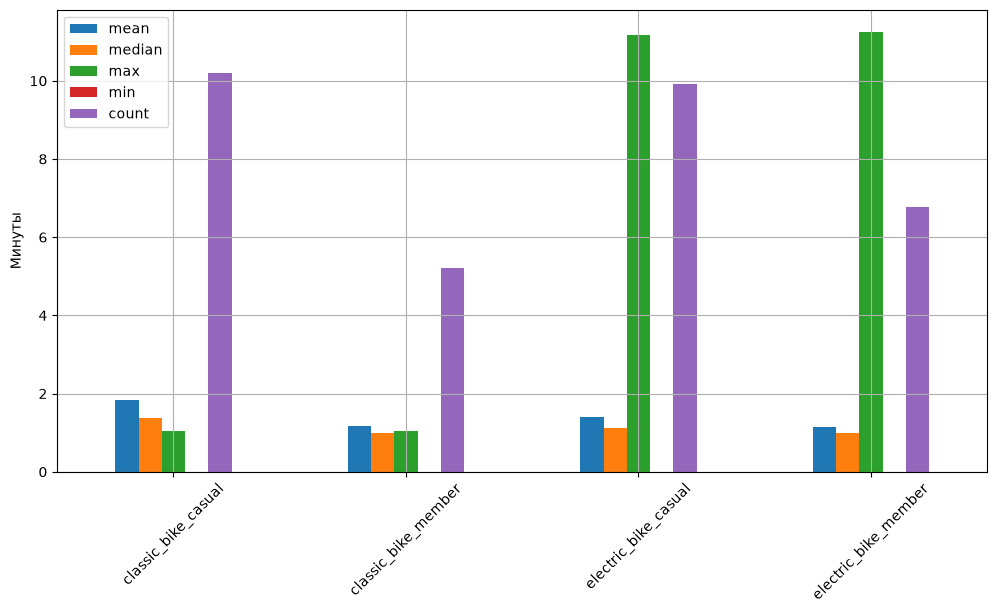

In [21]:
df_heat.index = (
    df_heat['rideable_type'].astype(str)
    + '_'
    + df_heat['member_casual'].astype(str)
)

df_heat[['mean', 'median', 'max', 'min', 'count']].plot(
    kind='bar',
    figsize=(12, 6)
)
plt.ylabel("Минуты")
plt.xticks(rotation=45)
plt.grid(True)
plt.show()

- строю тепловую карту

<Axes: >

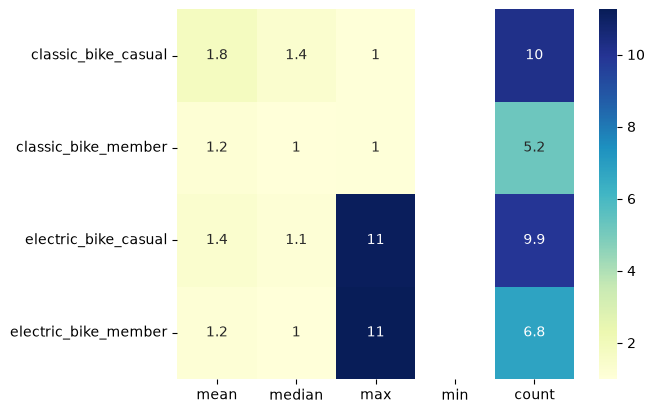

In [22]:
sns.heatmap(
    df_heat[['mean', 'median', 'max', 'min', 'count']],
    annot=True,
    cmap='YlGnBu'
)

- откидываю поездки боллее 20 минут

In [23]:
ride_to_work_less_20 = ride_to_work[ride_to_work['duration_in_minutes'] <= 20]

- снова делаю ту же группировку (поездки на работу)

In [24]:
ride_to_work_less_20_group = ride_to_work_less_20.groupby(
    ['rideable_type', 'member_casual']
)['duration_in_minutes'].agg(['mean', 'median', 'max', 'min', 'count'])

ride_to_work_less_20_group

mean     median   max  min   count
rideable_type member_casual                                         
classic_bike  casual          9.967363   9.536900  20.0  0.0  182167
              member          8.851348   8.200000  20.0  0.0  690987
docked_bike   casual         11.244167  11.283334  20.0  0.0   25801
              member          9.243839   8.566667  20.0  0.0   52710
electric_bike casual          9.287907   8.850000  20.0  0.0  108641
              member          8.765175   8.216666  20.0  0.0  258697

- откидываю поездки боллее 20 минут (поездки домой)

In [25]:
ride_to_home_less_20 = ride_to_home[ride_to_home['duration_in_minutes'] <= 20]

- снова делаю ту же группировку (поездки на работу)

In [26]:
ride_to_home_less_20_group = ride_to_home_less_20.groupby(
    ['rideable_type', 'member_casual']
)['duration_in_minutes'].agg(['mean', 'median', 'max', 'min', 'count'])

ride_to_home_less_20_group

mean     median   max  min   count
rideable_type member_casual                                         
classic_bike  casual         10.664089  10.466666  20.0  0.0  349617
              member          8.914052   8.233334  20.0  0.0  961780
docked_bike   casual         11.777901  12.016666  20.0  0.0   69493
              member          9.537526   8.933333  20.0  0.0   93532
electric_bike casual          9.470004   9.100000  20.0  0.0  210677
              member          8.749715   8.133333  20.0  0.0  393740

- выбираю поездики вне поездок на работу и обратно домой

In [27]:
ride_without_work_less_20 = ride_without_work[ride_without_work['duration_in_minutes'] <= 20]

- делаю группировку для данных вне поездок на работу и домой

In [28]:
ride_without_work_less_20_group = ride_without_work_less_20.groupby(
    ['rideable_type', 'member_casual']
)['duration_in_minutes'].agg(['mean', 'median', 'max', 'min', 'count'])

ride_without_work_less_20_group

mean     median   max  min    count
rideable_type member_casual                                          
classic_bike  casual         10.532305  10.283334  20.0  0.0  1419894
              member          8.569064   7.800000  20.0  0.0  3437721
docked_bike   casual         11.779091  12.000000  20.0  0.0   314503
              member          9.484597   8.866667  20.0  0.0   372590
electric_bike casual          9.285172   8.800000  20.0  0.0   951772
              member          8.434949   7.733333  20.0  0.0  1659775

- делю поездки вне работы на поездки на работу, которые длятся менее 20 минут

In [29]:
df_heat_work_less_20 = ride_without_work_less_20_group / ride_to_work_less_20_group
df_heat_work_less_20

mean    median  max  min      count
rideable_type member_casual                                         
classic_bike  casual         1.056679  1.078268  1.0  NaN   7.794463
              member         0.968108  0.951220  1.0  NaN   4.975088
docked_bike   casual         1.047573  1.063515  1.0  NaN  12.189566
              member         1.026045  1.035020  1.0  NaN   7.068678
electric_bike casual         0.999706  0.994350  1.0  NaN   8.760707
              member         0.962325  0.941176  1.0  NaN   6.415904

- вывожу тепловой график (поездки на работу)

<Axes: ylabel='rideable_type-member_casual'>

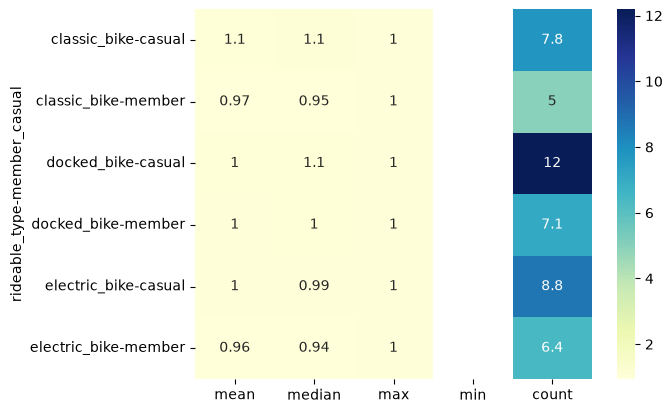

In [30]:
sns.heatmap(
    df_heat_work_less_20[['mean', 'median', 'max', 'min', 'count']],
    annot=True,
    cmap='YlGnBu'
)

- делю поездки вне работы на поездки домой, которые длятся менее 20 минут

In [31]:
df_heat_home_less_20 = ride_without_work_less_20_group / ride_to_home_less_20_group
df_heat_home_less_20

mean    median  max  min     count
rideable_type member_casual                                        
classic_bike  casual         0.987642  0.982484  1.0  NaN  4.061284
              member         0.961298  0.947368  1.0  NaN  3.574332
docked_bike   casual         1.000101  0.998613  1.0  NaN  4.525679
              member         0.994450  0.992537  1.0  NaN  3.983556
electric_bike casual         0.980482  0.967033  1.0  NaN  4.517683
              member         0.964026  0.950820  1.0  NaN  4.215409

- вывожу тепловую карту (поездки домой)

<Axes: ylabel='rideable_type-member_casual'>

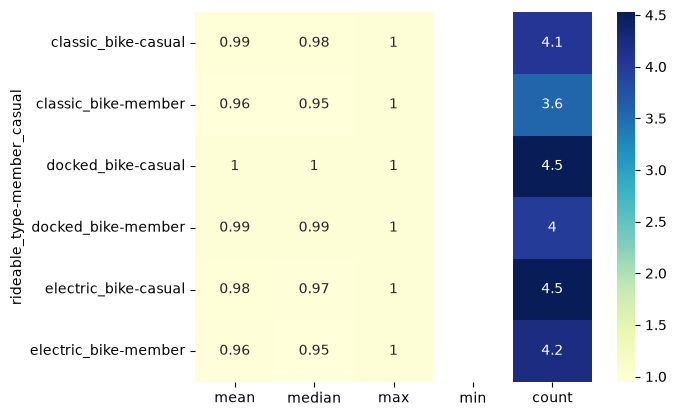

In [32]:
sns.heatmap(
    df_heat_home_less_20[['mean', 'median', 'max', 'min', 'count']],
    annot=True,
    cmap='YlGnBu'
)

### Вывод по гипотезе 1 - Можно ли увеличить количество аренды в такие часы как с 8 до 9 и с 18 до 19 тариф на работу и домой.
- Доля поездок на работу и домой занимает 28.04% (это и так 4 часа каждый день)
- Что менять по тарифному плану пока не стоит
- В ходе анализа данных рекомендованно занятся развитием аренды велосипедов в не рабочее время